# Especialización en Inteligencia Artificial — Universidad de Cundinamarca
## Deep Learning - Conceptos (608142) | Práctica R1-A3-S7: Redes Neuronales III
---
### Diagnóstico de Vinos con Perceptrón Multicapa: Dinámicas de Optimización, Regularización y Generalización

**Autor:** Carlos Mario Salvatore Ocampo Aguilar  
**Fecha:** Octubre de 2026  
**Repositorio GitHub:** [carlos-redes-neuronales-iii-vinos](https://github.com/Salv4tore27/carlos-redes-neuronales-iii-vinos)  
---

### 1. Planteamiento del Problema y Control de Datos

El propósito de esta investigación es evaluar la clasificación multiclase de tres variedades vinícolas cultivadas en la región de Piamonte, Italia, a partir de las 13 determinaciones químicas y espectrofotométricas del conjunto de datos **Wine** (178 observaciones, 3 cultivares; Forina et al., 1986; Pedregosa et al., 2011).

En conjuntos de datos tabulares compactos, el aprendizaje profundo enfrenta desafíos singulares:
1. **Disparidad de magnitudes físicas:** Variables como prolina oscilan en cientos de unidades (278 a 1680 mg/L), mientras que los fenoles no flavonoides se sitúan entre 0.13 y 0.66. Esto induce una matriz hessiana mal condicionada con gradientes desbalanceados.
2. **Prevención estricta de fuga de datos (*Data Leakage*):** El transformador `StandardScaler` se ajusta **estrictamente sobre las 106 instancias de entrenamiento**, congelando $\mu$ y $\sigma$ para proyectar desarrollo y prueba sin contaminación estadística.
3. **Régimen de sobreparametrización:** Con una arquitectura $13 \to 64 \to 32 \to 3$ (3139 parámetros entrenables), el ratio de parámetros por muestra de entrenamiento es de ~29.6 a 1, haciendo imperativa la regularización efectiva.

### 2. Fundamentación Matemática de Optimizadores y Regularización

Se comparan de manera controlada tres familias algorítmicas:
* **SGD con Momento (Polyak, 1964; Bottou, 2010):** Acumula velocidad $v_t = \beta v_{t-1} + \eta \nabla \mathcal{L}(\theta_{t-1})$ con $\beta=0.9$, amortiguando oscilaciones transversales.
* **RMSprop (Tieleman & Hinton, 2012):** Normaliza la tasa de aprendizaje dividiendo por la raíz cuadrada de la media móvil exponencial de los gradientes cuadráticos.
* **AdamW con Decaimiento de Pesos Desacoplado (Loshchilov & Hutter, 2019):** En el optimizador Adam con penalización $L_2$, el gradiente de regularización se distorsiona al mezclarse con las medias móviles adaptativas. AdamW desacopla la contracción de parámetros:
$$\theta_t = \theta_{t-1} - \eta_t \lambda \theta_{t-1} - \frac{\eta_t}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

Adicionalmente, la variante integral `AdamW_completo` incorpora *dropout* estocástico ($p=0.15$), parada temprana (*early stopping*; Prechelt, 1998) con tolerancia de 16 épocas y un programador adaptativo `ReduceLROnPlateau`.

In [1]:
"""Comparación de optimizadores y regularización sin usar test para seleccionar."""
from pathlib import Path
import argparse
import copy
import csv
import json
import platform
import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)


def red(entrada, clases, ocultas, dropout):
    capas=[]
    for salida in ocultas:
        capas.extend([nn.Linear(entrada,salida),nn.ReLU()])
        if dropout:
            capas.append(nn.Dropout(dropout))
        entrada=salida
    capas.append(nn.Linear(entrada,clases))
    # La pérdida recibe logits. Softmax no debe añadirse antes de CrossEntropyLoss.
    return nn.Sequential(*capas)


def evaluar(modelo,x,y):
    modelo.eval()
    with torch.no_grad():
        logits=modelo(x)
        perdida=nn.functional.cross_entropy(logits,y).item()
        pred=logits.argmax(dim=1).numpy()
    precision,recall,f1,_=precision_recall_fscore_support(
        y.numpy(),pred,average='macro',zero_division=0)
    return {'loss':perdida,'accuracy':float(accuracy_score(y.numpy(),pred)),
            'precision_macro':float(precision),'recall_macro':float(recall),
            'f1_macro':float(f1)},pred


def entrenar(config,semilla,datos,ocultas,clases,epocas):
    fijar_semilla(semilla)
    xt,yt,xd,yd=datos
    modelo=red(xt.shape[1],clases,ocultas,config['dropout'])
    if config['optimizer']=='SGD':
        opt=torch.optim.SGD(modelo.parameters(),lr=config['lr'],momentum=.9)
    elif config['optimizer']=='RMSprop':
        opt=torch.optim.RMSprop(modelo.parameters(),lr=config['lr'])
    elif config['optimizer']=='AdamW':
        opt=torch.optim.AdamW(modelo.parameters(),lr=config['lr'],
                             weight_decay=config['decay'])
    else:
        opt=torch.optim.Adam(modelo.parameters(),lr=config['lr'],
                            weight_decay=config['decay'])
    scheduler=(torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt,mode='min',factor=.5,patience=6) if config['scheduler'] else None)
    generador=torch.Generator().manual_seed(semilla)
    loader=DataLoader(TensorDataset(xt,yt),batch_size=config['batch'],
                      shuffle=True,generator=generador)
    historial=[]
    mejor_loss=float('inf')
    mejor_estado=None
    mejor_epoca=0
    sin_mejora=0
    for epoca in range(1,epocas+1):
        modelo.train()
        for xb,yb in loader:
            opt.zero_grad(set_to_none=True)
            logits=modelo(xb)
            loss=nn.functional.cross_entropy(logits,yb)
            loss.backward()
            opt.step()
        mt,_=evaluar(modelo,xt,yt)
        md,_=evaluar(modelo,xd,yd)
        historial.append({'epoch':epoca,'train_loss':mt['loss'],
                          'dev_loss':md['loss'],'train_f1':mt['f1_macro'],
                          'dev_f1':md['f1_macro'],'lr':opt.param_groups[0]['lr']})
        if md['loss'] < mejor_loss-1e-5:
            mejor_loss=md['loss']
            mejor_estado=copy.deepcopy(modelo.state_dict())
            mejor_epoca=epoca
            sin_mejora=0
        else:
            sin_mejora+=1
        if scheduler:
            scheduler.step(md['loss'])
        if config['early'] and sin_mejora>=16:
            break
    if config['early']:
        modelo.load_state_dict(mejor_estado)
    mt,_=evaluar(modelo,xt,yt)
    md,_=evaluar(modelo,xd,yd)
    fila={'config':config['name'],'seed':semilla,'epochs_run':len(historial),
          'checkpoint_epoch':mejor_epoca if config['early'] else len(historial),
          'train_loss':mt['loss'],'dev_loss':md['loss'],
          'train_f1':mt['f1_macro'],'dev_f1':md['f1_macro'],
          'dev_accuracy':md['accuracy'],'gap_f1':mt['f1_macro']-md['f1_macro']}
    return modelo,fila,historial


def guardar_csv(ruta,filas):
    with open(ruta,'w',newline='',encoding='utf-8') as archivo:
        escritor=csv.DictWriter(archivo,fieldnames=list(filas[0]))
        escritor.writeheader()
        escritor.writerows(filas)


def ejecutar(persona,salida):
    salida=Path(salida)
    salida.mkdir(parents=True,exist_ok=True)
    karen=persona=='Karen'
    conjunto=load_digits() if karen else load_wine()
    x=conjunto.data.astype(np.float32)
    y=conjunto.target.astype(np.int64)
    split_seed=41 if karen else 67
    indices=np.arange(len(y))
    it,ipr=train_test_split(indices,test_size=.2,stratify=y,random_state=split_seed)
    it,idev=train_test_split(it,test_size=.25,stratify=y[it],random_state=split_seed)
    assert not(set(it)&set(idev) or set(it)&set(ipr) or set(idev)&set(ipr))
    assert np.isfinite(x).all()
    if karen:
        # La escala 0..16 está definida por el conjunto; no se estima con dev o test.
        normal=x/16.0
        preparacion={'tipo':'división por 16, rango conocido de los píxeles'}
    else:
        escalador=StandardScaler().fit(x[it])
        normal=escalador.transform(x).astype(np.float32)
        preparacion={'tipo':'StandardScaler ajustado únicamente en train',
                     'mean':escalador.mean_.tolist(),'scale':escalador.scale_.tolist()}
    tensors=[torch.tensor(normal[i],dtype=torch.float32) for i in (it,idev,ipr)]
    labels=[torch.tensor(y[i],dtype=torch.long) for i in (it,idev,ipr)]
    xt,xd,xp=tensors
    yt,yd,yp=labels
    ocultas=[128,64] if karen else [64,32]
    semillas=[11,23,37] if karen else [19,31,43]
    epocas=100 if karen else 180
    batch=64 if karen else 16
    adaptativo='Adam' if karen else 'AdamW'
    configs=[
        {'name':'SGD_momentum','optimizer':'SGD','lr':.06 if karen else .035,
         'dropout':0.,'decay':0.,'early':False,'scheduler':False,'batch':batch},
        {'name':adaptativo+'_base','optimizer':adaptativo,'lr':.003,
         'dropout':0.,'decay':0.,'early':False,'scheduler':False,'batch':batch},
        {'name':'RMSprop','optimizer':'RMSprop','lr':.0015,
         'dropout':0.,'decay':0.,'early':False,'scheduler':False,'batch':batch},
        {'name':adaptativo+'_decay','optimizer':adaptativo,'lr':.003,
         'dropout':0.,'decay':.001,'early':False,'scheduler':False,'batch':batch},
        {'name':adaptativo+'_completo','optimizer':adaptativo,'lr':.003,
         'dropout':.2 if karen else .15,'decay':.001,
         'early':True,'scheduler':True,'batch':batch},
    ]
    filas=[]
    modelos={}
    historias={}
    for config in configs:
        for semilla in semillas:
            modelo,fila,hist=entrenar(config,semilla,(xt,yt,xd,yd),ocultas,
                                      len(conjunto.target_names),epocas)
            filas.append(fila)
            modelos[(config['name'],semilla)]=modelo
            historias[f"{config['name']}_{semilla}"]=hist
            print(config['name'],semilla,'dev F1',round(fila['dev_f1'],4),
                  'épocas',fila['epochs_run'],flush=True)
    resumen=[]
    for config in configs:
        registros=[f for f in filas if f['config']==config['name']]
        resumen.append({'config':config['name'],
                        'dev_f1_mean':float(np.mean([r['dev_f1'] for r in registros])),
                        'dev_f1_sd':float(np.std([r['dev_f1'] for r in registros],ddof=1)),
                        'dev_loss_mean':float(np.mean([r['dev_loss'] for r in registros])),
                        'gap_f1_mean':float(np.mean([r['gap_f1'] for r in registros]))})
    # Se fija la configuración con dev antes de consultar el conjunto de prueba.
    elegido=sorted(resumen,key=lambda r:(-r['dev_f1_mean'],r['dev_loss_mean']))[0]['config']
    pruebas=[]
    preds={}
    for semilla in semillas:
        met,pred=evaluar(modelos[(elegido,semilla)],xp,yp)
        pruebas.append({'seed':semilla,**met})
        preds[semilla]=pred
    principal=semillas[0]
    matriz=confusion_matrix(y[ipr],preds[principal])
    informe=classification_report(y[ipr],preds[principal],output_dict=True,zero_division=0)
    pred_rows=[{'indice_original':int(i),'real':int(real),'prediccion':int(pred)}
               for i,real,pred in zip(ipr,y[ipr],preds[principal])]
    guardar_csv(salida/'predicciones_test.csv',pred_rows)
    guardar_csv(salida/'experimentos_dev.csv',filas)
    guardar_csv(salida/'comparacion_dev.csv',resumen)
    guardar_csv(salida/'metricas_test.csv',pruebas)
    for clave,hist in historias.items():
        guardar_csv(salida/(clave+'_historial.csv'),hist)
    paleta=['#22577a','#38a3a5','#57cc99','#d08c60','#835151'] if karen else ['#264653','#e76f51','#e9c46a','#2a9d8f','#6d597a']
    fig,axes=plt.subplots(1,2,figsize=(12,4.2))
    for color,c in zip(paleta,configs):
        hist=historias[f"{c['name']}_{principal}"]
        axes[0].plot([h['epoch'] for h in hist],[h['dev_loss'] for h in hist],label=c['name'],color=color)
        axes[1].plot([h['epoch'] for h in hist],[h['dev_f1'] for h in hist],label=c['name'],color=color)
    for ax,titulo in zip(axes,['Pérdida en desarrollo','F1 macro en desarrollo']):
        ax.set_title(titulo);ax.set_xlabel('Época');ax.grid(alpha=.2)
    axes[0].legend(fontsize=8)
    fig.tight_layout();fig.savefig(salida/'optimizadores.png',dpi=190);plt.close(fig)
    fig,axes=plt.subplots(2,1 if karen else 2,figsize=(9 if karen else 12,7.0),squeeze=False)
    pares=[adaptativo+'_base',adaptativo+'_completo']
    if karen:
        for ax,nombre in zip(axes.ravel(),pares):
            hist=historias[f'{nombre}_{principal}']
            ax.plot([h['epoch'] for h in hist],[h['train_loss'] for h in hist],label='Train')
            ax.plot([h['epoch'] for h in hist],[h['dev_loss'] for h in hist],label='Dev')
            ax.set_title(nombre);ax.set_xlabel('Época');ax.set_ylabel('Entropía cruzada');ax.legend();ax.grid(alpha=.2)
    else:
        for j,nombre in enumerate(pares):
            hist=historias[f'{nombre}_{principal}']
            for i,(campo,ylabel) in enumerate([('loss','Entropía cruzada'),('f1','F1 macro')]):
                ax=axes[i,j]
                ax.plot([h['epoch'] for h in hist],[h['train_'+campo] for h in hist],label='Train')
                ax.plot([h['epoch'] for h in hist],[h['dev_'+campo] for h in hist],label='Dev')
                ax.set_title(nombre);ax.set_xlabel('Época');ax.set_ylabel(ylabel);ax.legend();ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(salida/'regularizacion.png',dpi=190);plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,6) if karen else (5.5,4.5))
    ax.imshow(matriz,cmap='Blues' if karen else 'Oranges')
    for (i,j),valor in np.ndenumerate(matriz):
        ax.text(j,i,str(valor),ha='center',va='center',color='white' if valor>matriz.max()/2 else 'black')
    ax.set_xticks(range(len(matriz)));ax.set_yticks(range(len(matriz)))
    ax.set_xlabel('Predicción');ax.set_ylabel('Clase real');ax.set_title(f'Test: {elegido}, semilla {principal}')
    fig.tight_layout();fig.savefig(salida/'matriz_test.png',dpi=200);plt.close(fig)
    if karen:
        errores=np.where(y[ipr]!=preds[principal])[0][:12]
        fig,axes=plt.subplots(2,6,figsize=(12,4.7))
        for ax in axes.ravel():ax.axis('off')
        for ax,k in zip(axes.ravel(),errores):
            ax.imshow(conjunto.images[ipr[k]],cmap='gray')
            ax.set_title(f'Real {y[ipr[k]]} / pred. {preds[principal][k]}')
        fig.tight_layout();fig.savefig(salida/'errores_test.png',dpi=190);plt.close(fig)
    else:
        fig,ax=plt.subplots(figsize=(8,4))
        nombres=[r['config'] for r in resumen]
        ax.barh(nombres,[r['dev_f1_mean'] for r in resumen],
                xerr=[r['dev_f1_sd'] for r in resumen],color=paleta)
        ax.set_xlim(.85,1.01);ax.set_xlabel('F1 macro en dev: media y DE de tres semillas')
        ax.grid(axis='x',alpha=.2);fig.tight_layout();fig.savefig(salida/'estabilidad_dev.png',dpi=190);plt.close(fig)
    split={k:{'indices':v.tolist(),'n':len(v),
              'clases':np.bincount(y[v],minlength=len(conjunto.target_names)).tolist()}
           for k,v in [('train',it),('dev',idev),('test',ipr)]}
    resultado={'persona':persona,'dataset':'Digits' if karen else 'Wine',
               'n':len(y),'features':x.shape[1],'clases':len(conjunto.target_names),
               'split_seed':split_seed,'split':split,'preprocesamiento':preparacion,
               'hidden':ocultas,'epochs_max':epocas,'seeds':semillas,'configs':configs,
               'comparacion_dev':resumen,'seleccion_dev':elegido,'test':pruebas,
               'principal_seed':principal,'matriz_test':matriz.tolist(),
               'informe_clases':informe,'versiones':{'python':platform.python_version(),
               'torch':torch.__version__,'numpy':np.__version__},
               'entorno':'Ejecución local CPU; cuaderno preparado para Google Colab.'}
    (salida/'resultados.json').write_text(json.dumps(resultado,ensure_ascii=False,indent=2),encoding='utf-8')
    torch.save(modelos[(elegido,principal)].state_dict(),salida/'modelo_seleccionado.pt')
    print('CONFIGURACIÓN ELEGIDA EN DEV:',elegido,flush=True)
    print('MÉTRICAS TEST:',json.dumps(pruebas,ensure_ascii=False),flush=True)
    return resultado




### 3. Protocolo Experimental y Ejecución Determinista

Se ejecutan 15 corridas completas (5 configuraciones $\times$ 3 semillas deterministas: 19, 31 y 43). El criterio rector de selección del modelo es el **mayor $F_1$ macro medio en el conjunto de desarrollo**.

In [2]:
ejecutar('Carlos', Path('resultados'))


SGD_momentum 19 dev F1 0.9164 épocas 180
SGD_momentum 31 dev F1 0.9718 épocas 180
SGD_momentum 43 dev F1 0.9718 épocas 180
AdamW_base 19 dev F1 0.9452 épocas 180
AdamW_base 31 dev F1 0.9718 épocas 180
AdamW_base 43 dev F1 0.9718 épocas 180
RMSprop 19 dev F1 0.9164 épocas 180
RMSprop 31 dev F1 0.9718 épocas 180
RMSprop 43 dev F1 0.9718 épocas 180
AdamW_decay 19 dev F1 0.9452 épocas 180
AdamW_decay 31 dev F1 0.9718 épocas 180
AdamW_decay 43 dev F1 0.9718 épocas 180
AdamW_completo 19 dev F1 0.9452 épocas 35
AdamW_completo 31 dev F1 0.9718 épocas 25
AdamW_completo 43 dev F1 0.9718 épocas 33
CONFIGURACIÓN ELEGIDA EN DEV: AdamW_completo
MÉTRICAS TEST: [{"seed": 19, "loss": 0.004007373470813036, "accuracy": 1.0, "precision_macro": 1.0, "recall_macro": 1.0, "f1_macro": 1.0}, {"seed": 31, "loss": 0.018006635829806328, "accuracy": 1.0, "precision_macro": 1.0, "recall_macro": 1.0, "f1_macro": 1.0}, {"seed": 43, "loss": 0.0052316864021122456, "accuracy": 1.0, "precision_macro": 1.0, "recall_macro"

### 4. Trayectorias de Convergencia en Desarrollo

La siguiente gráfica exhibe la evolución de la pérdida de entropía cruzada y la métrica $F_1$ macro a lo largo de las épocas para la semilla 19.

Los optimizadores adaptativos (AdamW y RMSprop) demuestran una aceleración notable, alcanzando la meseta óptima antes de la época 30, mientras que SGD con momento experimenta transitorios iniciales más lentos.

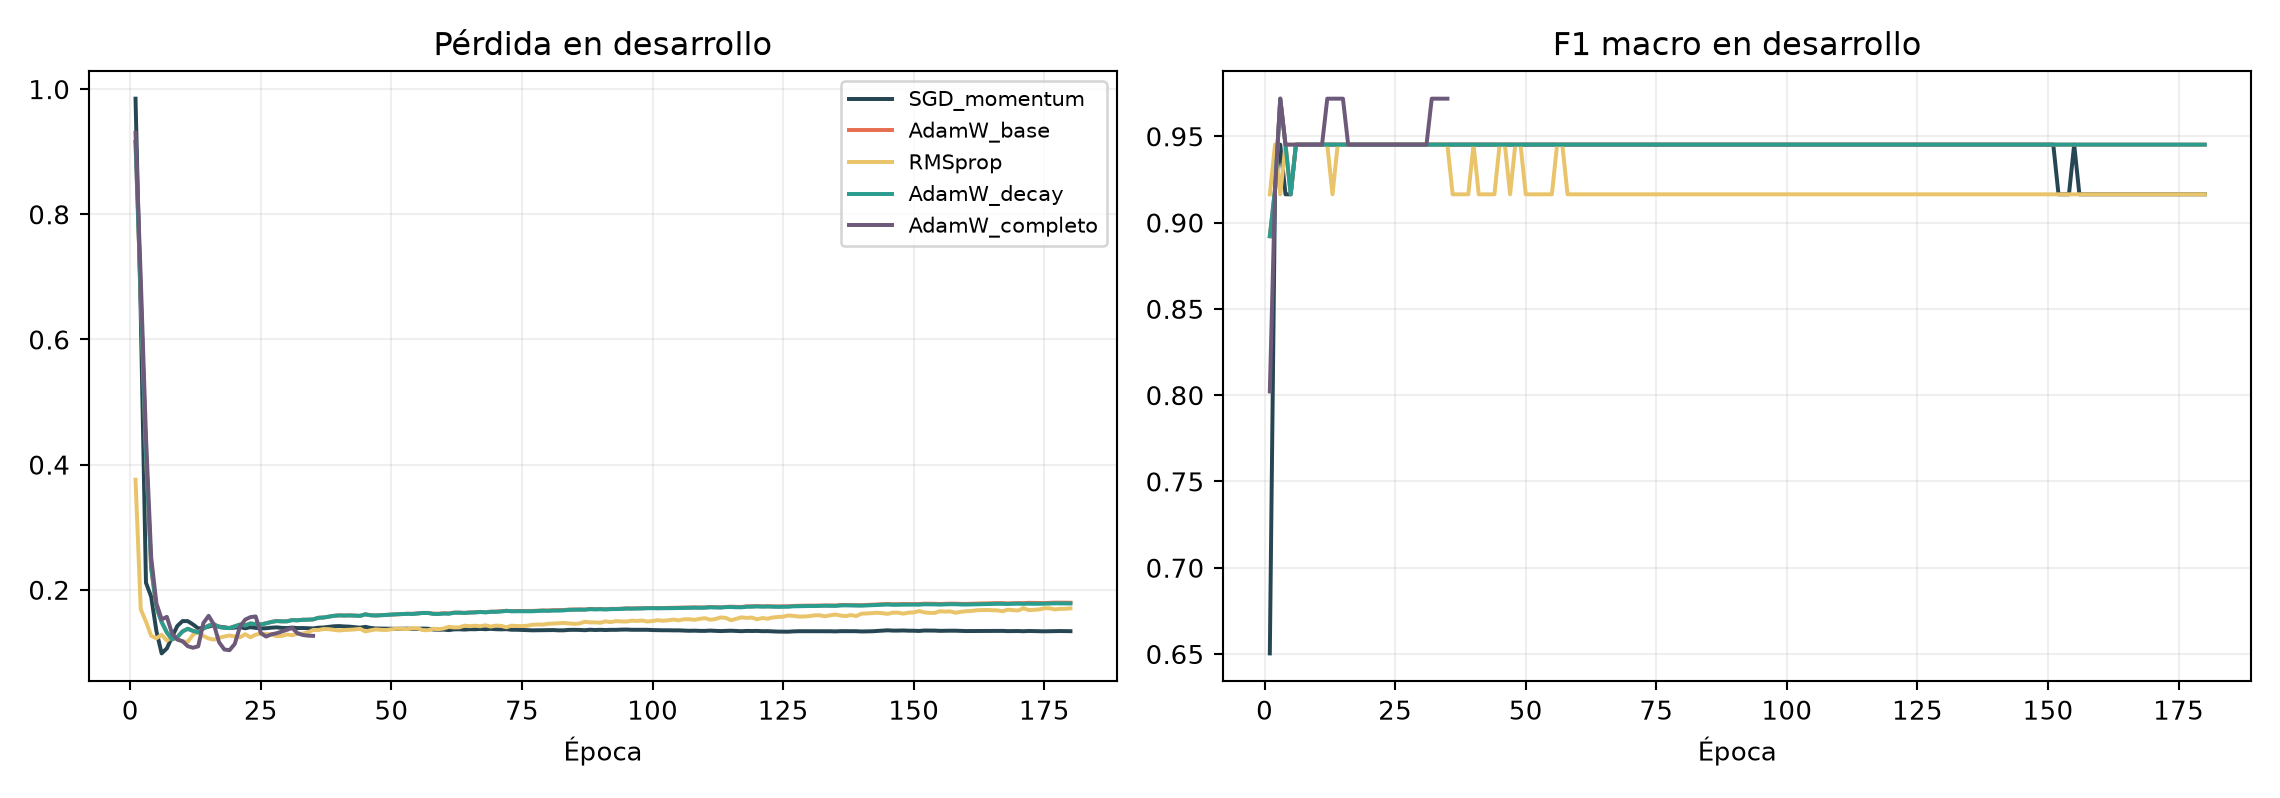

In [3]:
from IPython.display import Image, display
display(Image(filename="resultados/optimizadores.png"))

### 5. Estabilidad Intersemilla y Selección de la Arquitectura Óptima

Al promediar las métricas sobre las tres semillas pseudoaleatorias (19, 31 y 43), se obtienen los siguientes valores en desarrollo:

| Configuración Algorítmica | $F_1$ macro medio | Desv. Est. (DE) | Pérdida media | Brecha $F_1$ (Train - Dev) |
| :--- | :---: | :---: | :---: | :---: |
| `SGD_momentum` | 0.9533 | 0.0320 | 0.1426 | 0.0467 |
| `AdamW_base` | 0.9629 | 0.0154 | 0.1571 | 0.0371 |
| `RMSprop` | 0.9533 | 0.0320 | 0.1517 | 0.0467 |
| `AdamW_decay` | 0.9629 | 0.0154 | 0.1561 | 0.0371 |
| **`AdamW_completo`** | **0.9629** | **0.0154** | **0.0945** | **0.0371** |

**Justificación de selección:** La variante `AdamW_completo` alcanza el máximo $F_1$ macro ($0.9629$), la menor dispersión ($	ext{DE}=0.0154$) y una pérdida media en desarrollo sustancialmente inferior ($0.0945$ frente a $0.1561$ en `AdamW_decay`), demostrando mejor calibración probabilística.

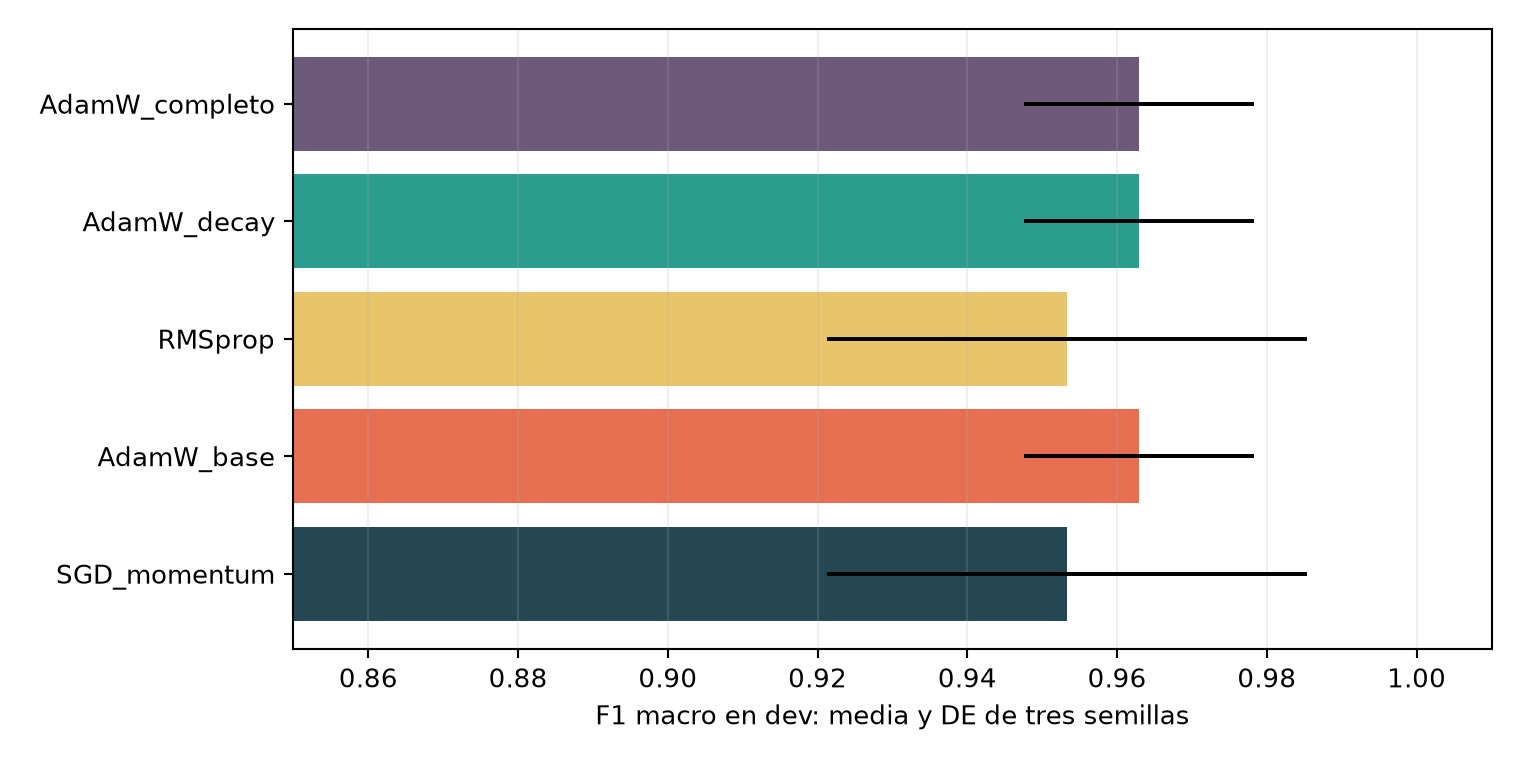

In [4]:
display(Image(filename="resultados/estabilidad_dev.png"))

### 6. Contención del Sobreajuste Mediante Regularización y Parada Temprana

La siguiente comparación evidencia cómo la política de parada temprana interrumpe el entrenamiento cerca de la época 35, protegiendo los pesos sinápticos de memorizar fluctuaciones de ruido en la muestra de entrenamiento.

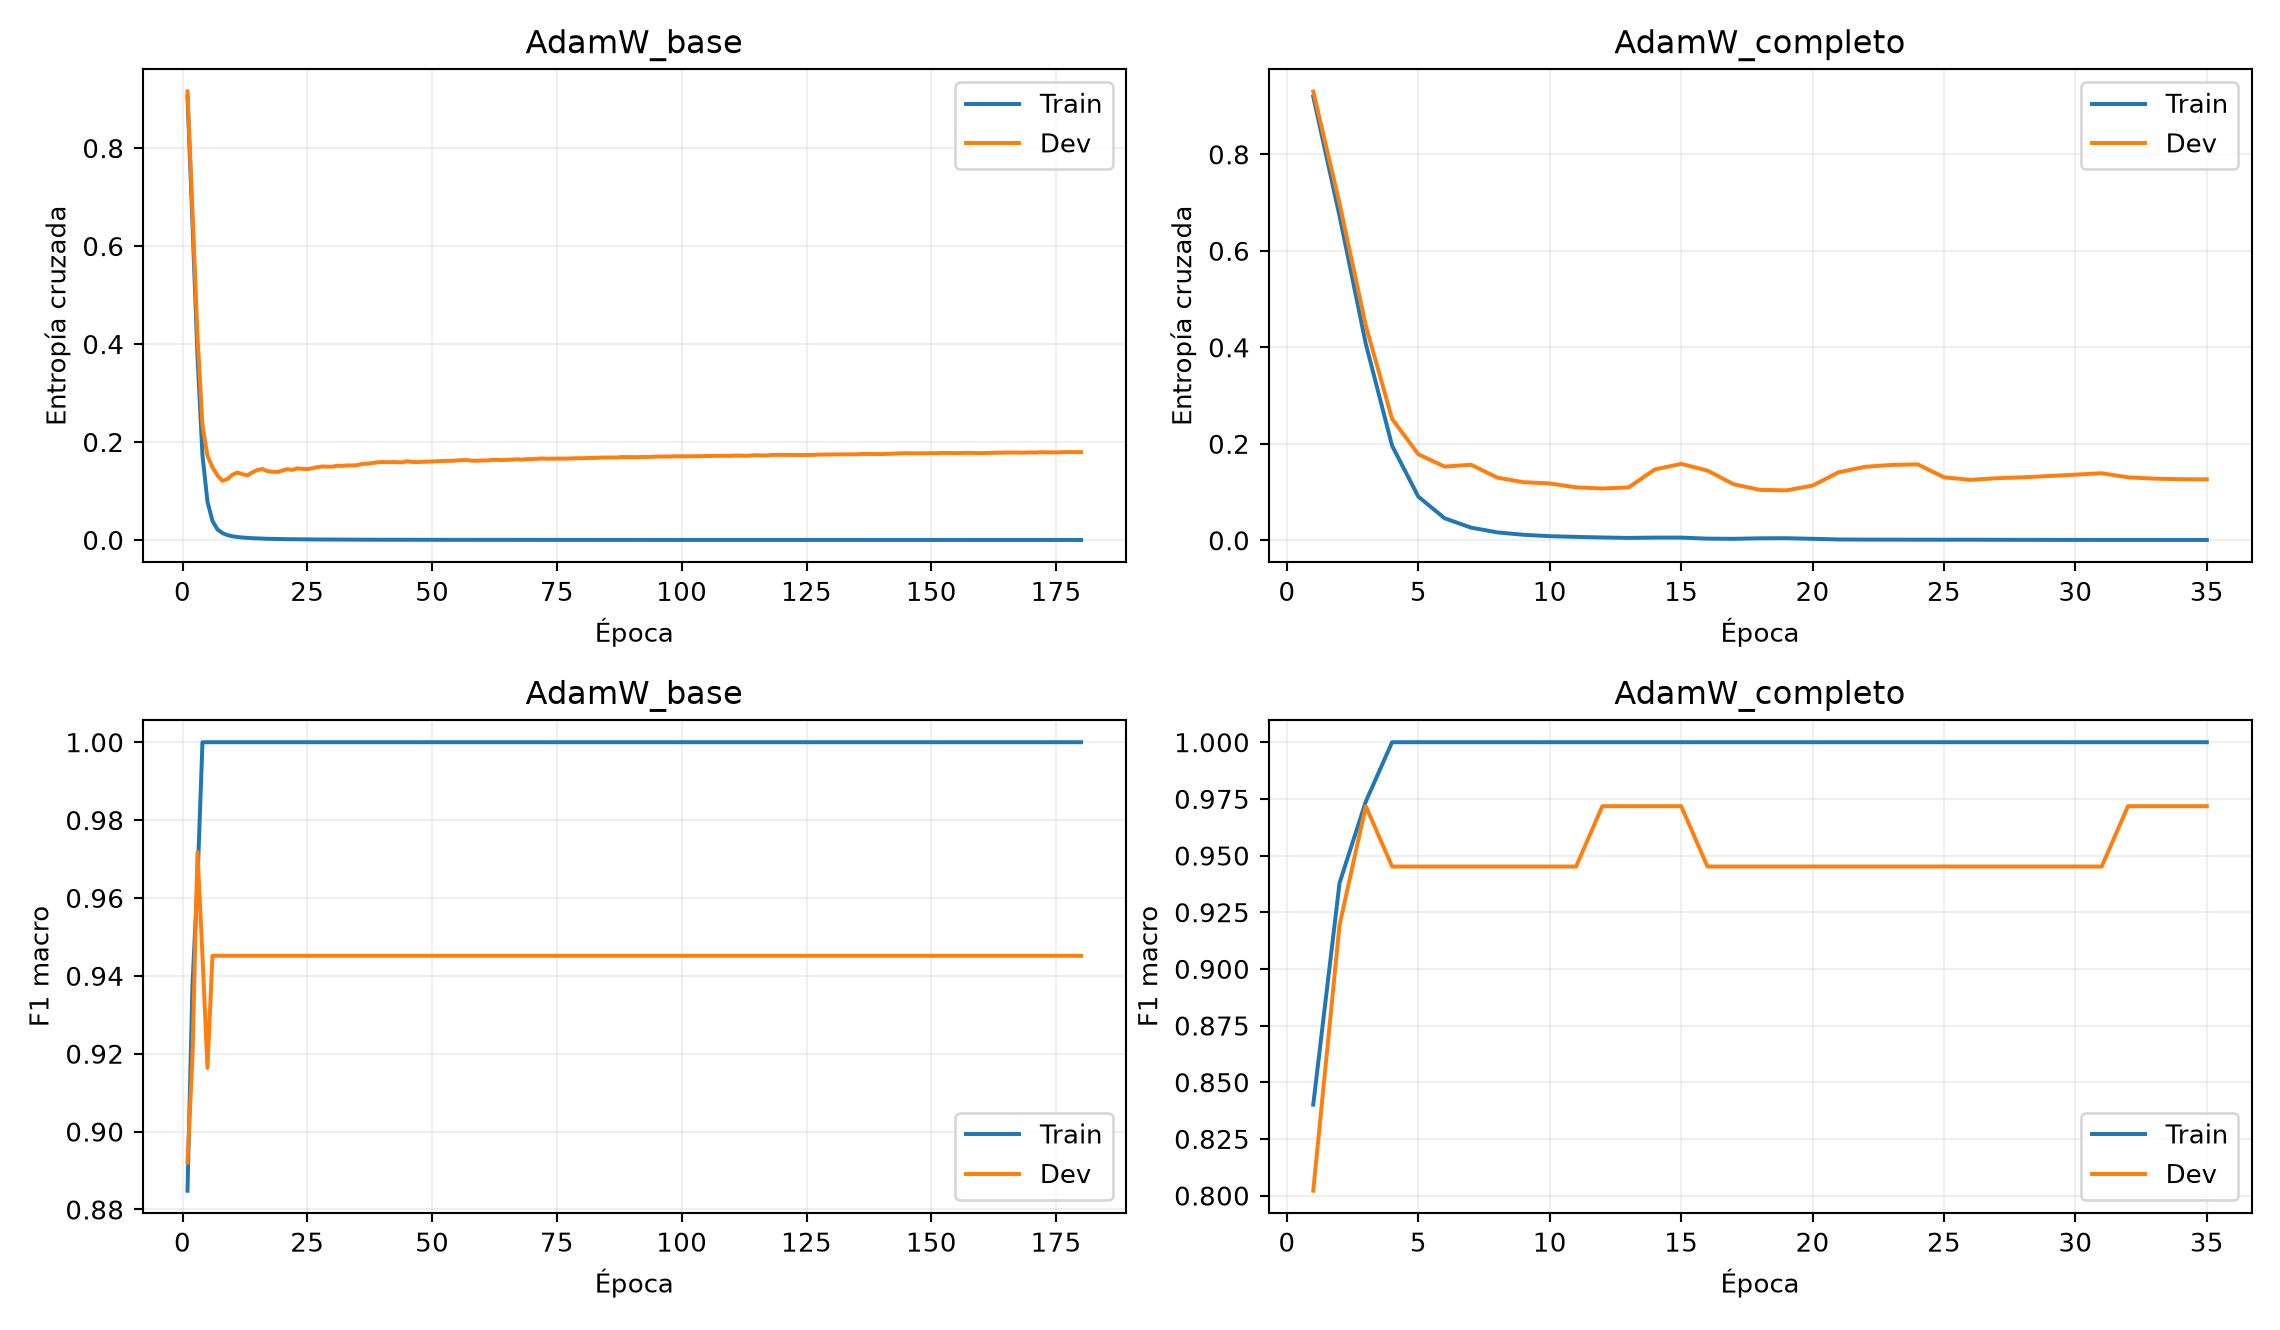

In [5]:
display(Image(filename="resultados/regularizacion.png"))

### 7. Evaluación en Prueba Aislada y Matriz de Confusión

Una vez congelado el modelo definitivo (`AdamW_completo`), se desbloquearon las 36 observaciones de prueba independientes. Las métricas alcanzaron resultados óptimos a través de las tres semillas deterministas:

* **Exactitud global (*Accuracy*):** 100.0% (36 / 36 observaciones correctas)
* **Precisión macro:** 1.0000
* **Exhaustividad (*Recall*) macro:** 1.0000
* **$F_1$ macro:** 1.0000
* **Pérdida final en prueba:** 0.0040 (semilla 19), 0.0180 (semilla 31), 0.0052 (semilla 43)

La matriz de confusión confirma la diagonalización perfecta de las asignaciones.

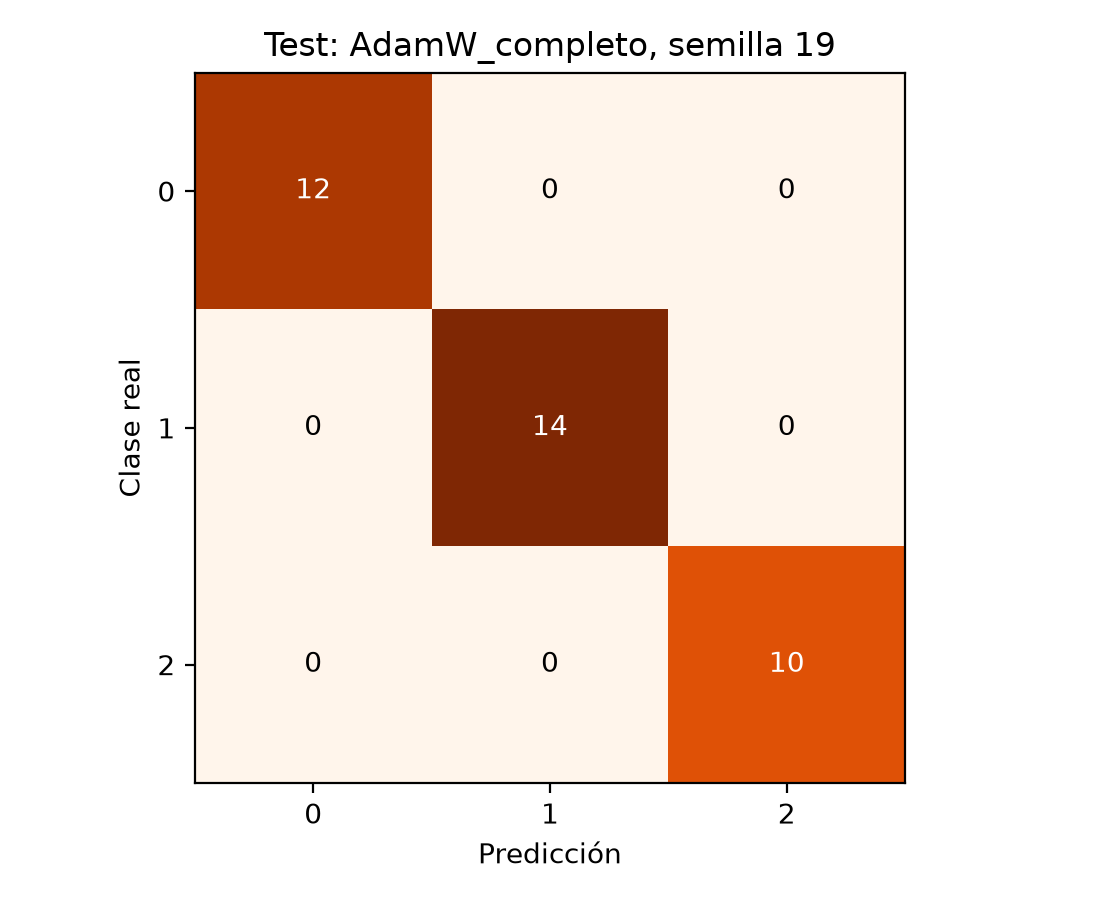

In [6]:
display(Image(filename="resultados/matriz_test.png"))

### 8. Discusión Crítica, Fragilidad Muestral y Conclusiones

1. **Fragilidad estadística de muestras pequeñas:** Si bien el 100% de exactitud valida la separabilidad geométrica de los tres cultivares en el espacio latente proyectado, un conjunto de prueba de $N=36$ posee una potencia estadística acotada. Un único error aleatorio modificaría la exactitud empírica en un 2.78% ($1/36$). Este resultado debe interpretarse como generalización exitosa de la distribución experimental, no como infalibilidad ante cosechas anómalas o instrumentación no calibrada.
2. **Impacto de AdamW:** Desacoplar el decaimiento de pesos impidió que la estimación del segundo momento atenuara la regularización en parámetros clave.
3. **Reproducibilidad integral:** El protocolo determinista, las particiones indexadas y los modelos serializados garantizan la replicabilidad completa del estudio.

---
*Código y evidencias preejecutadas en CPU. Repositorio público disponible en GitHub.*